In [4]:
import numpy as np, pandas as pd

ROOT = r"C:\Users\Vidhaan\Documents\UCI HAR Dataset\UCI HAR Dataset"
SIGNALS = ["body_acc_x","body_acc_y","body_acc_z",
           "body_gyro_x","body_gyro_y","body_gyro_z",
           "total_acc_x","total_acc_y","total_acc_z"]

def load(split):
    X = np.stack([
        np.loadtxt(f"{ROOT}/{split}/Inertial Signals/{s}_{split}.txt")
        for s in SIGNALS], axis=-1)              # (N, 128, 9)
    y = np.loadtxt(f"{ROOT}/{split}/y_{split}.txt", dtype=int) - 1   # 0-5
    subj = np.loadtxt(f"{ROOT}/{split}/subject_{split}.txt", dtype=int)
    return X, y, subj

X_train, y_train, s_train = load("train")
X_test,  y_test,  s_test  = load("test")
print(X_train.shape, X_test.shape)
print(np.bincount(y_train))

(7352, 128, 9) (2947, 128, 9)
[1226 1073  986 1286 1374 1407]


In [10]:
%matplotlib inline
import matplotlib.pyplot as plt

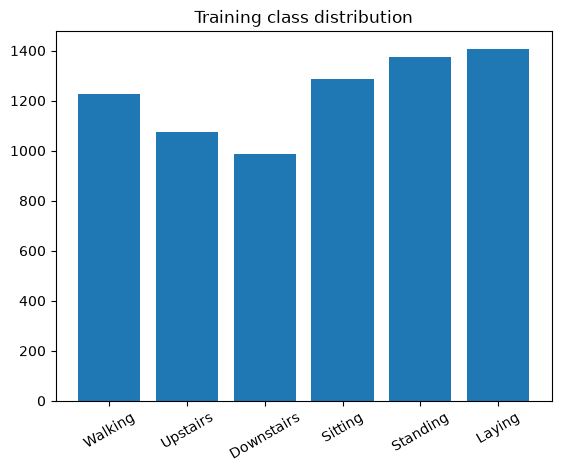

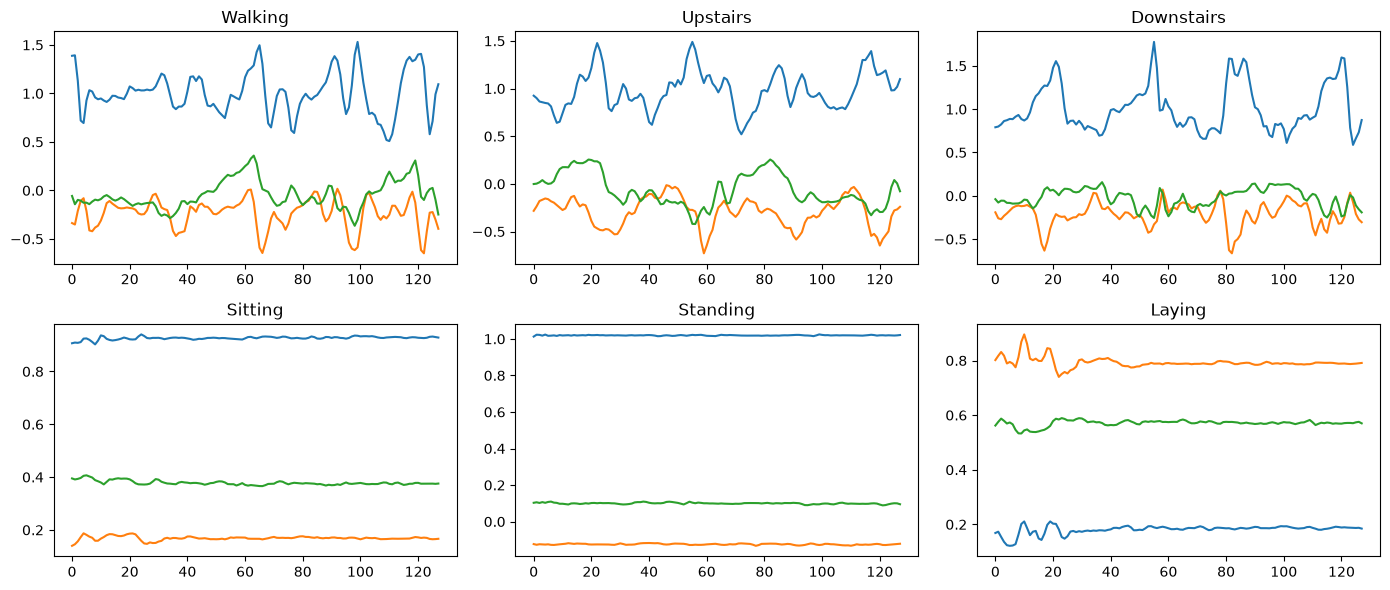

21 train subjects; validation subjects: [ 1 27 25  3]
(5879, 128, 9) (1473, 128, 9)


In [11]:
import matplotlib.pyplot as plt
%matplotlib inline

names = ["Walking","Upstairs","Downstairs","Sitting","Standing","Laying"]

# 1. class balance
plt.bar(names, np.bincount(y_train))
plt.title("Training class distribution"); plt.xticks(rotation=30); plt.show()

# 2. one window per activity (total_acc channels)
fig, axs = plt.subplots(2, 3, figsize=(14, 6))
for k, ax in enumerate(axs.ravel()):
    i = np.where(y_train == k)[0][0]
    ax.plot(X_train[i, :, 6:9])
    ax.set_title(names[k])
plt.tight_layout(); plt.show()

# 3. subject-wise validation split
subjects = np.unique(s_train)
rng = np.random.RandomState(42)
val_subj = rng.choice(subjects, 4, replace=False)
val_mask = np.isin(s_train, val_subj)

X_tr, y_tr = X_train[~val_mask], y_train[~val_mask]
X_val, y_val = X_train[val_mask], y_train[val_mask]
print(len(subjects), "train subjects; validation subjects:", val_subj)
print(X_tr.shape, X_val.shape)

# 4. normalise using TRAIN statistics only
mean = X_tr.mean(axis=(0, 1), keepdims=True)
std = X_tr.std(axis=(0, 1), keepdims=True) + 1e-8
X_tr = (X_tr - mean) / std
X_val = (X_val - mean) / std
X_te = (X_test - mean) / std

Epoch 1/60
92/92 - 8s - 82ms/step - accuracy: 0.5839 - loss: 1.0993 - val_accuracy: 0.7237 - val_loss: 0.6657
Epoch 2/60
92/92 - 6s - 63ms/step - accuracy: 0.8607 - loss: 0.4098 - val_accuracy: 0.9627 - val_loss: 0.1844
Epoch 3/60
92/92 - 11s - 116ms/step - accuracy: 0.9197 - loss: 0.2147 - val_accuracy: 0.9104 - val_loss: 0.3688
Epoch 4/60
92/92 - 10s - 109ms/step - accuracy: 0.9286 - loss: 0.1773 - val_accuracy: 0.9504 - val_loss: 0.1523
Epoch 5/60
92/92 - 11s - 115ms/step - accuracy: 0.9383 - loss: 0.1480 - val_accuracy: 0.9233 - val_loss: 0.2920
Epoch 6/60
92/92 - 6s - 66ms/step - accuracy: 0.9360 - loss: 0.1529 - val_accuracy: 0.9579 - val_loss: 0.1567
Epoch 7/60
92/92 - 5s - 59ms/step - accuracy: 0.9440 - loss: 0.1363 - val_accuracy: 0.9701 - val_loss: 0.1251
Epoch 8/60
92/92 - 4s - 49ms/step - accuracy: 0.9369 - loss: 0.1445 - val_accuracy: 0.9606 - val_loss: 0.1859
Epoch 9/60
92/92 - 5s - 52ms/step - accuracy: 0.9372 - loss: 0.1421 - val_accuracy: 0.9633 - val_loss: 0.1256
Epoc

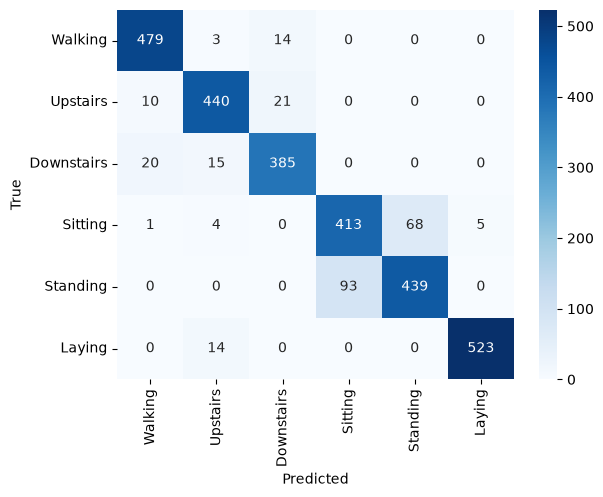

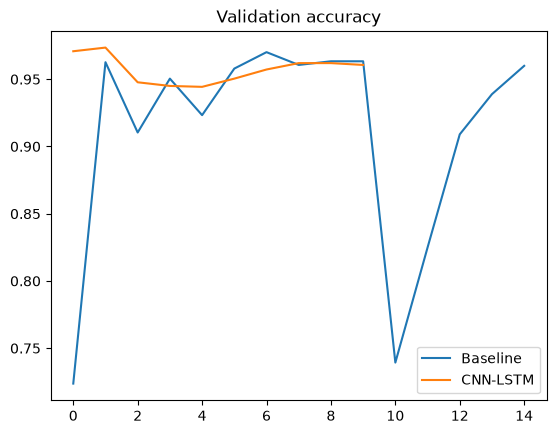

In [14]:
import tensorflow as tf
from tensorflow.keras import layers, models, callbacks
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

tf.keras.utils.set_random_seed(42)

def train_eval(model, name):
    model.compile(optimizer="adam",
                  loss="sparse_categorical_crossentropy",
                  metrics=["accuracy"])
    es = callbacks.EarlyStopping(monitor="val_loss", patience=8,
                                 restore_best_weights=True)
    hist = model.fit(X_tr, y_tr, validation_data=(X_val, y_val),
                     epochs=60, batch_size=64, callbacks=[es], verbose=2)
    loss, acc = model.evaluate(X_te, y_test, verbose=0)
    print(f"{name} test accuracy: {acc:.4f}")
    return hist

# Baseline: plain LSTM
baseline = models.Sequential([
    layers.Input(shape=(128, 9)),
    layers.LSTM(64),
    layers.Dropout(0.3),
    layers.Dense(64, activation="relu"),
    layers.Dense(6, activation="softmax")])
h_base = train_eval(baseline, "Baseline LSTM")

# Hybrid: CNN-LSTM
hybrid = models.Sequential([
    layers.Input(shape=(128, 9)),
    layers.Conv1D(64, 5, activation="relu", padding="same"),
    layers.MaxPooling1D(2),
    layers.Conv1D(128, 5, activation="relu", padding="same"),
    layers.MaxPooling1D(2),
    layers.LSTM(64),
    layers.Dropout(0.3),
    layers.Dense(64, activation="relu"),
    layers.Dense(6, activation="softmax")])
h_hyb = train_eval(hybrid, "CNN-LSTM")

# Evaluation of the hybrid
pred = hybrid.predict(X_te).argmax(axis=1)
print(classification_report(y_test, pred, target_names=names))
cm = confusion_matrix(y_test, pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=names, yticklabels=names)
plt.xlabel("Predicted"); plt.ylabel("True"); plt.show()

# Training curves
for h, t in [(h_base, "Baseline"), (h_hyb, "CNN-LSTM")]:
    plt.plot(h.history["val_accuracy"], label=t)
plt.title("Validation accuracy"); plt.legend(); plt.show()